# DATA 245 · Group 6 — EDA & Baseline Models
**Goal:** predict whether a person's annual income exceeds **$50K** from demographic and work attributes, understand which features drive it, and check how fair the predictions are across groups.

**Metrics:** **F1** on the >50K class (classes are imbalanced, so accuracy alone flatters a model), **ROC-AUC** (threshold-free ranking quality), and **accuracy** for reference.
**Fairness note:** sex and race are *input features here for EDA only*; we report true-positive rate and positive-prediction rate per group to see where errors concentrate.

> Switch datasets with the single `DATASET` variable below: `"adult"` (UCI Adult, 1994) or `"acs_income"` (folktables ACSIncome, CA 2018).

In [1]:
DATASET = "adult"  # "adult" or "acs_income"

In [2]:
# Parameters
DATASET = "acs_income"


> **Credit.** Pipeline and plotting helpers adapted from Nelson, Fridhi & Wagner, LMU CMSI 3300 HW4 (2022), reused with instructor approval.
> (`src/models.py::S_Pred` and the model-comparison loop; `src/viz.py` confusion-matrix, ROC and feature-importance plots. Fixed: `class_weight='balanced'` instead of the backwards `{'<=50K': 1.4}`; all columns are driven by the dataset config.)

## Setup

In [3]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from datasets import load_dataset
import models as M
import viz as V

V.set_theme()
pd.set_option("display.float_format", "{:,.3f}".format)
df, cfg = load_dataset(DATASET)
FIG_DIR = PROJECT_ROOT / "reports" / "figures" / DATASET
T, POS = cfg["target"], cfg["positive_label"]
say = lambda s: display(Markdown(s))
say(f"Loaded **{cfg['title']}**: {len(df):,} rows after cleaning (raw: {cfg['n_raw']:,}). Target: {cfg['target_desc']}. Figures → `{FIG_DIR.relative_to(PROJECT_ROOT)}`")

Loaded **ACSIncome (CA 2018, 1-Year)**: 195,665 rows after cleaning (raw: 378,817). Target: personal income (PINCP) > $50,000. Figures → `reports/figures/acs_income`

## 1 · Data overview

In [4]:
display(df.head())
overview = pd.DataFrame({"dtype": df.dtypes.astype(str), "n_unique": df.nunique(),
                         "missing": df.isna().sum()})
display(overview)

,Age,Class of Worker,Education,Marital Status,Occupation,Birthplace,Relationship,Weekly Work Hours,Sex,Race,Income
0,30,Self-employed (not inc.),Less than HS,Married,Transportation,US (state),Institutional group quarters,40,Male,Some Other Race,<=50K
1,21,State government,HS diploma / GED,Never married,Science,US (state),Non-institutional group quarters,20,Male,White,<=50K
2,65,Private not-for-profit,Master's,Never married,Community & Social,US (state),Non-institutional group quarters,8,Male,White,<=50K
3,33,Private for-profit,Less than HS,Divorced,Transportation,US (state),Institutional group quarters,40,Male,White,<=50K
4,18,Private not-for-profit,Some college,Never married,Computer & Math,US (state),Non-institutional group quarters,18,Female,White,<=50K


,dtype,n_unique,missing
Age,int64,75,0
Class of Worker,str,8,0
Education,str,8,0
Marital Status,str,5,0
Occupation,str,26,0
Birthplace,str,8,0
Relationship,str,18,0
Weekly Work Hours,int64,95,0
Sex,str,2,0
Race,str,9,0


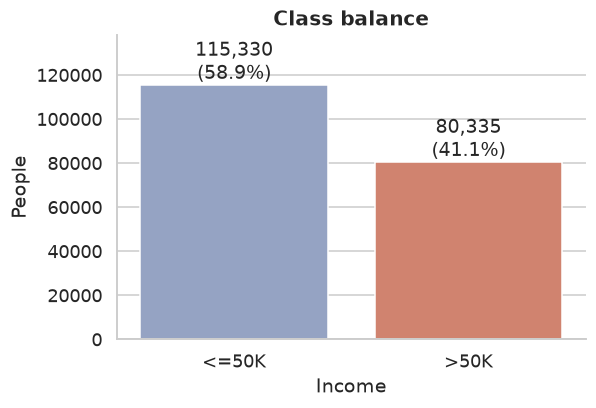

**Takeaway:** 195,665 rows × 10 features (2 numeric, 8 categorical); 0 missing values remain after cleaning. The positive class (>50K) is **41.1%** of rows, so a model that always predicts '<=50K' would already score 58.9% accuracy — hence F1/AUC as headline metrics.

In [5]:
base = (df[T] == POS).mean()
fig = V.save(V.class_balance(df, cfg), FIG_DIR, "01_class_balance"); plt.show()
say(f"**Takeaway:** {df.shape[0]:,} rows × {df.shape[1]-1} features ({len(cfg['numeric_cols'])} numeric, "
    f"{len(cfg['categorical_cols'])} categorical); {int(df.isna().sum().sum())} missing values remain after cleaning. "
    f"The positive class ({POS}) is **{base:.1%}** of rows, so a model that always predicts '{cfg['negative_label']}' "
    f"would already score {1-base:.1%} accuracy — hence F1/AUC as headline metrics.")

In [6]:
display(df[cfg["numeric_cols"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,"195,665.000",42.735,14.885,17.000,30.000,42.000,55.000,94.000
Weekly Work Hours,"195,665.000",37.867,13.019,1.000,32.000,40.000,40.000,99.000


## 2 · Univariate views
### 2a · Numeric features by income class

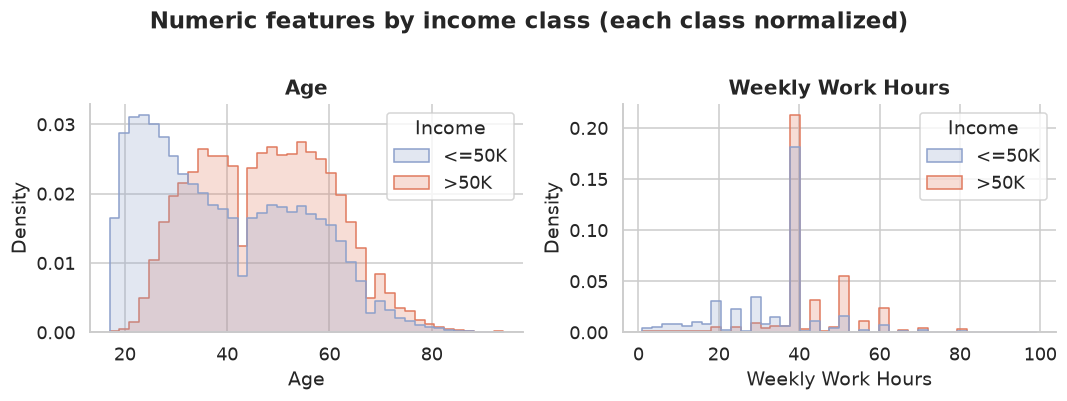

Income,<=50K,>50K
Age,37.000,47.000
Weekly Work Hours,40.000,40.000


**Takeaway:** median gap (>50K minus ≤50K): Age +10, Weekly Work Hours +0. Mean gap: Age +8.1, Weekly Work Hours +9.0. The biggest relative separation is in **Weekly Work Hours** (gap in standard deviations).

In [7]:
fig = V.save(V.numeric_by_class(df, cfg), FIG_DIR, "02_numeric_by_class"); plt.show()
med = df.groupby(T)[cfg["numeric_cols"]].median().T
display(med)
gaps = (med[POS] - med[cfg["negative_label"]])
mgap = df.groupby(T)[cfg["numeric_cols"]].mean().T
mgap = mgap[POS] - mgap[cfg["negative_label"]]
say("**Takeaway:** median gap (>50K minus ≤50K): " + ", ".join(f"{c} {g:+.0f}" for c, g in gaps.items()) +
    ". Mean gap: " + ", ".join(f"{c} {g:+,.1f}" for c, g in mgap.items()) +
    f". The biggest relative separation is in **{(mgap / df[cfg['numeric_cols']].std()).idxmax()}** (gap in standard deviations).")

### 2b · Categorical features: share earning >50K

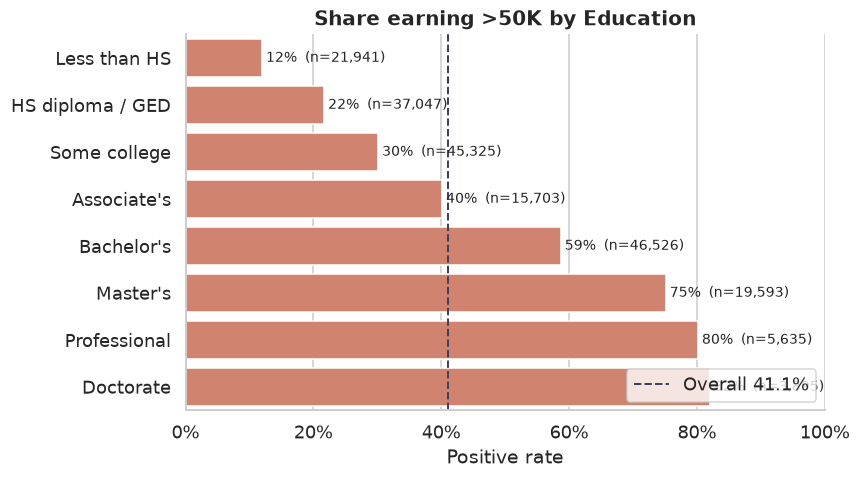

**Education:** highest rate *Doctorate* (82%), lowest *Less than HS* (12%); spread of 70 points (groups with n ≥ 100).

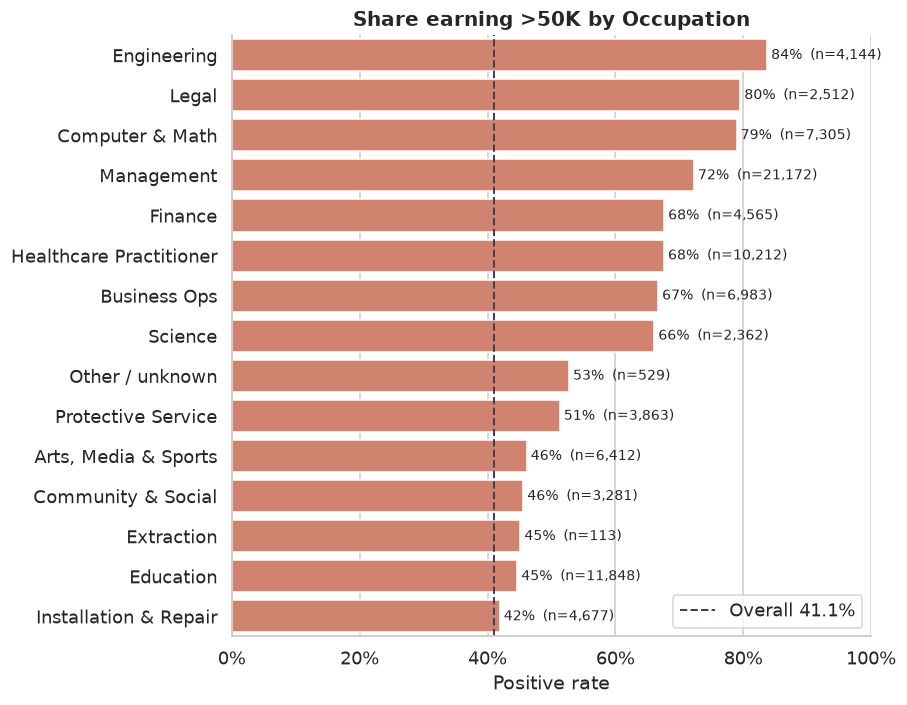

**Occupation:** highest rate *Engineering* (84%), lowest *Food Service* (6%); spread of 78 points (groups with n ≥ 100).

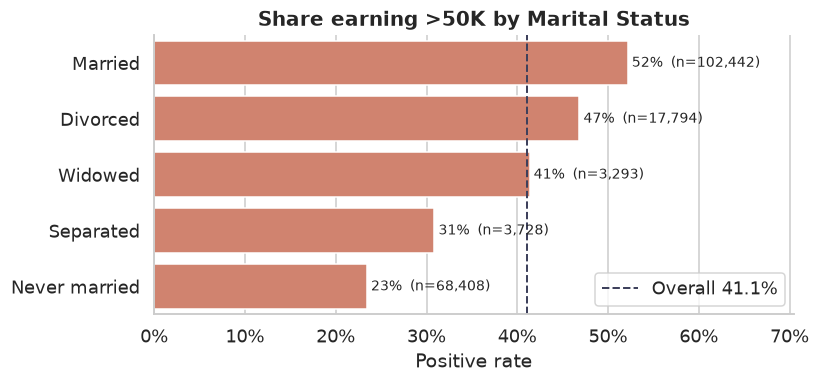

**Marital Status:** highest rate *Married* (52%), lowest *Never married* (23%); spread of 29 points (groups with n ≥ 100).

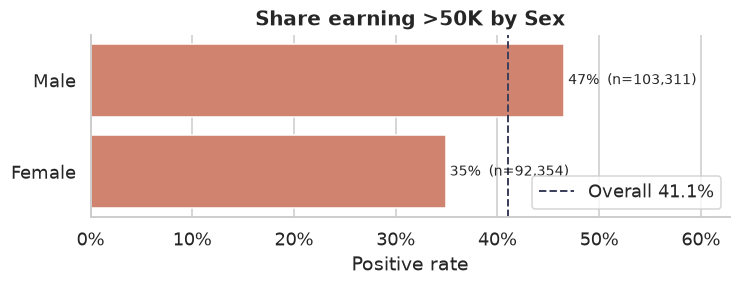

**Sex:** highest rate *Male* (47%), lowest *Female* (35%); spread of 12 points (groups with n ≥ 100).

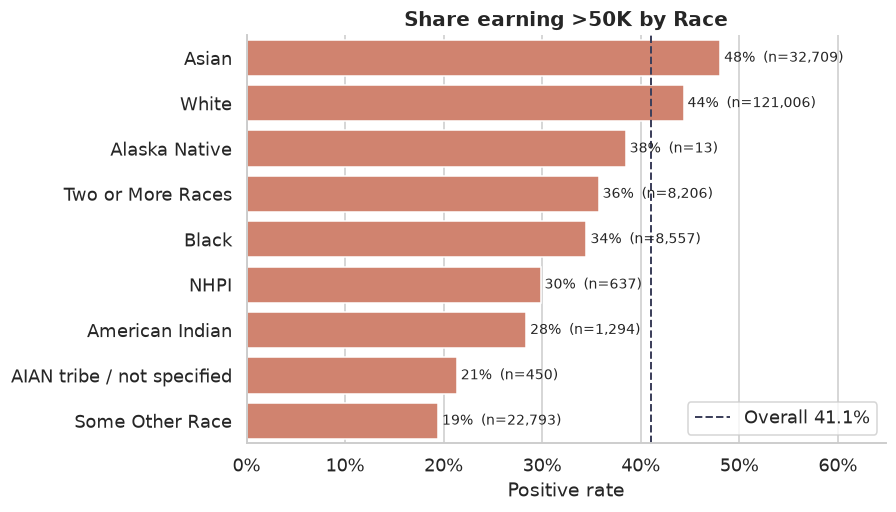

**Race:** highest rate *Asian* (48%), lowest *Some Other Race* (19%); spread of 29 points (groups with n ≥ 100).

In [8]:
rate_figs = {"Education": "03_rate_education", "Occupation": "04_rate_occupation",
             "Marital Status": "05_rate_marital", "Sex": "06_rate_sex", "Race": "07_rate_race"}
for col, name in rate_figs.items():
    V.save(V.positive_rate(df, cfg, col, order=cfg["category_orders"].get(col)), FIG_DIR, name); plt.show()
    r = df.groupby(col)[T].apply(lambda s: (s == POS).mean())
    n = df[col].value_counts()
    r = r[n[r.index] >= 100]
    say(f"**{col}:** highest rate *{r.idxmax()}* ({r.max():.0%}), lowest *{r.idxmin()}* ({r.min():.0%}); "
        f"spread of {100*(r.max()-r.min()):.0f} points (groups with n ≥ 100).")

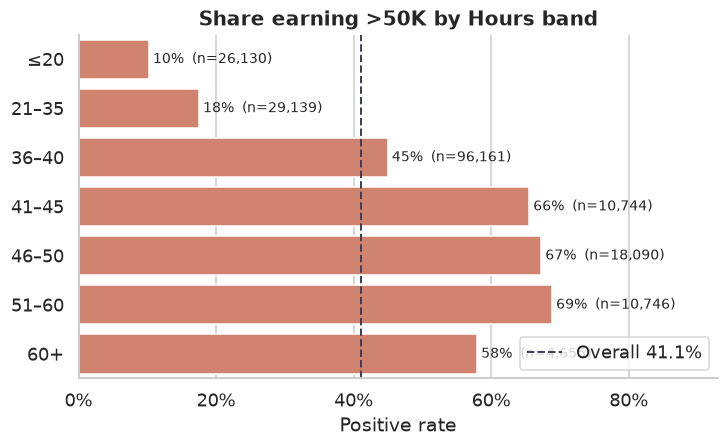

**Hours:** the >50K rate rises from 10% for ≤20 h/week to 69% at its peak (51–60 h).

In [9]:
bins = [0, 20, 35, 40, 45, 50, 60, 100]
hrs = pd.cut(df["Weekly Work Hours"], bins=bins, labels=["≤20", "21–35", "36–40", "41–45", "46–50", "51–60", "60+"])
tmp = df.assign(**{"Hours band": hrs})
V.save(V.positive_rate(tmp, cfg, "Hours band", order=list(hrs.cat.categories)), FIG_DIR, "08_rate_hours"); plt.show()
r = tmp.groupby("Hours band", observed=True)[T].apply(lambda s: (s == POS).mean())
say(f"**Hours:** the >50K rate rises from {r.iloc[0]:.0%} for ≤20 h/week to {r.max():.0%} at its peak ({r.idxmax()} h).")

## 3 · Correlation & association

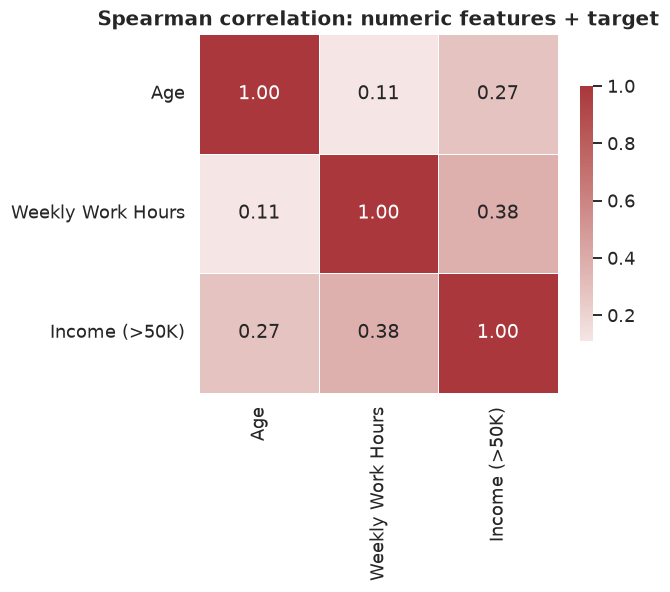

**Takeaway:** strongest numeric association with the target is **Weekly Work Hours** (ρ = 0.38); weakest is Age (ρ = 0.27).

In [10]:
num = df[cfg["numeric_cols"]].assign(**{f"{T} (>50K)": (df[T] == POS).astype(int)})
corr = num.corr(method="spearman")
V.save(V.corr_heatmap(corr, "Spearman correlation: numeric features + target"), FIG_DIR, "09_numeric_corr"); plt.show()
tc = corr[f"{T} (>50K)"].drop(f"{T} (>50K)").sort_values(ascending=False)
say(f"**Takeaway:** strongest numeric association with the target is **{tc.index[0]}** (ρ = {tc.iloc[0]:.2f}); "
    f"weakest is {tc.index[-1]} (ρ = {tc.iloc[-1]:.2f}).")

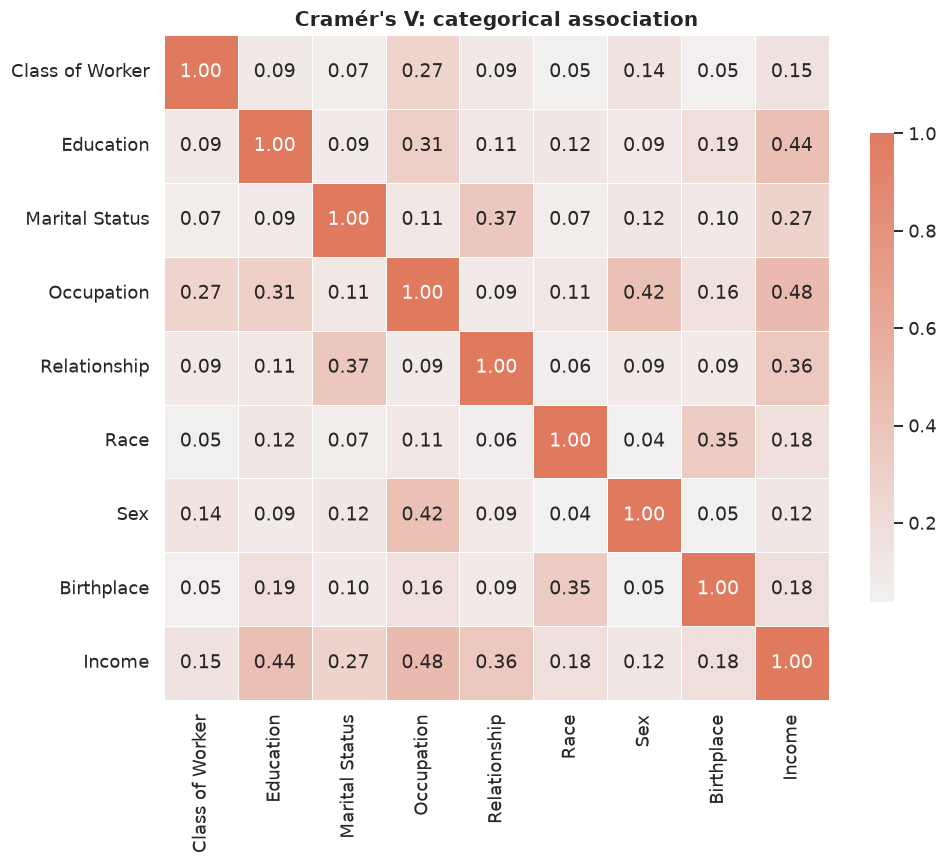

**Takeaway:** top categorical associations with income: Occupation (0.48), Education (0.44), Relationship (0.36). Note redundancy: Relationship ↔ Marital Status V = 0.37, Relationship ↔ Sex V = 0.09.

In [11]:
from scipy.stats import chi2_contingency
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2 = chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))
cats = cfg["categorical_cols"] + [T]
cv = pd.DataFrame([[cramers_v(df[a], df[b]) for b in cats] for a in cats], index=cats, columns=cats)
V.save(V.corr_heatmap(cv, "Cramér's V: categorical association", cmap=V.SEQ_CMAP, center=None), FIG_DIR, "10_cramers_v"); plt.show()
tv = cv[T].drop(T).sort_values(ascending=False)
say(f"**Takeaway:** top categorical associations with income: " +
    ", ".join(f"{k} ({v:.2f})" for k, v in tv.head(3).items()) +
    f". Note redundancy: Relationship ↔ Marital Status V = {cv.loc['Relationship','Marital Status']:.2f}, "
    f"Relationship ↔ Sex V = {cv.loc['Relationship','Sex']:.2f}.")

## 4 · Baseline: logistic regression (class_weight='balanced')
Stratified 80/20 split, `random_state=42`. Numerics median-imputed and standardized; categoricals one-hot encoded.

              precision    recall  f1-score   support

       <=50K      0.865     0.792     0.827     23066
        >50K      0.734     0.823     0.776     16067

    accuracy                          0.805     39133
   macro avg      0.799     0.807     0.801     39133
weighted avg      0.811     0.805     0.806     39133



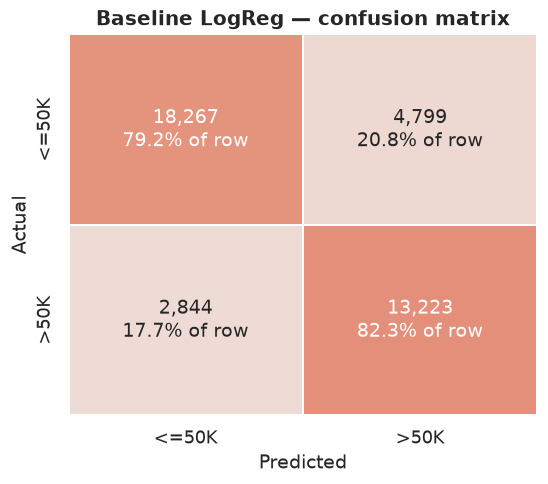

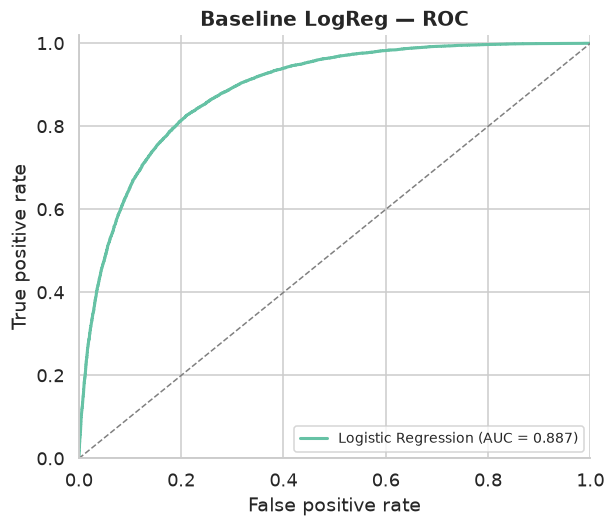

**Baseline:** accuracy 0.805, F1 0.776, ROC-AUC 0.887 on 39,133 test rows. Balanced weights trade precision for recall: it catches 82% of true >50K earners.

In [12]:
X_train, X_test, y_train, y_test = M.split(df, cfg)
base_model = M.S_Pred(cfg, scale=True).fit(X_train, y_train)
print(base_model.test_model(X_test, y_test))
bm = base_model.metrics(X_test, y_test)
y_pred = base_model.classify(X_test)
V.save(V.plot_confusion_matrix(y_test, y_pred, [cfg["negative_label"], POS], "Baseline LogReg — confusion matrix"), FIG_DIR, "11_baseline_confusion"); plt.show()
V.save(V.plot_roc_curve({"Logistic Regression": (y_test, base_model.score(X_test))}, "Baseline LogReg — ROC"), FIG_DIR, "12_baseline_roc"); plt.show()
tpr = y_pred[y_test == 1].mean()
say(f"**Baseline:** accuracy {bm['Accuracy']:.3f}, F1 {bm['F1']:.3f}, ROC-AUC {bm['ROC-AUC']:.3f} on {len(X_test):,} test rows. "
    f"Balanced weights trade precision for recall: it catches {tpr:.0%} of true >50K earners.")

## 5 · Model comparison
The HW4 comparison loop (one MLP config to keep runtime low). Training is capped at 60,000 stratified rows so both datasets run in a few minutes; the test set is always the full 20% hold-out.

Model,Accuracy,F1,ROC-AUC,Fit time (s)
Random Forest,0.810,0.779,0.895,7.1
Logistic Regression,0.803,0.775,0.887,0.3
MLP (64-32),0.814,0.774,0.896,4.7
Gradient Boosting,0.815,0.773,0.895,4.8
Decision Tree,0.776,0.754,0.856,0.6


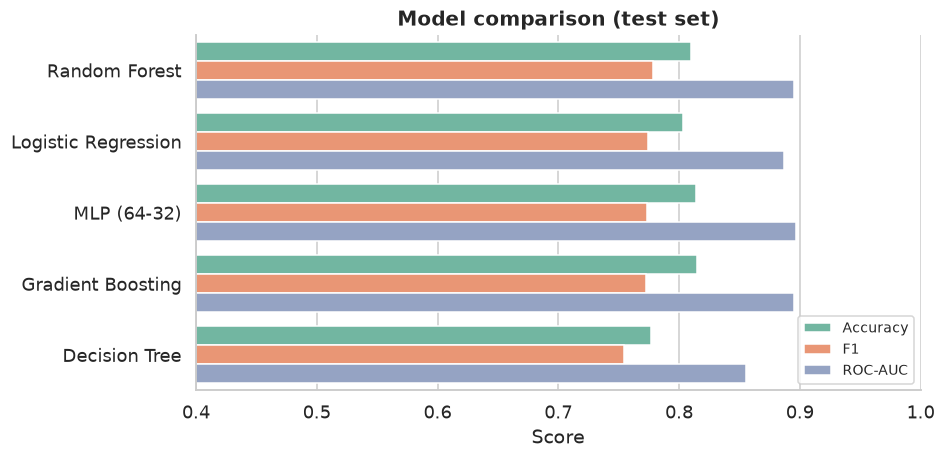

**Best by F1: Random Forest** — F1 0.779, AUC 0.895, accuracy 0.810 (vs. baseline LogReg F1 0.776). Highest AUC: MLP (64-32) (0.896).

In [13]:
res, fitted = M.compare_models(cfg, X_train, y_train, X_test, y_test, max_train_rows=60_000)
display(res.style.format({"Accuracy": "{:.3f}", "F1": "{:.3f}", "ROC-AUC": "{:.3f}", "Fit time (s)": "{:.1f}"})
        .background_gradient(subset=["F1", "ROC-AUC"], cmap="Oranges").hide(axis="index"))
V.save(V.model_comparison(res), FIG_DIR, "13_model_comparison"); plt.show()
best_name = res.loc[0, "Model"]; best = fitted[best_name]
res.to_csv(FIG_DIR / "model_comparison.csv", index=False)
say(f"**Best by F1: {best_name}** — F1 {res.loc[0,'F1']:.3f}, AUC {res.loc[0,'ROC-AUC']:.3f}, accuracy {res.loc[0,'Accuracy']:.3f} "
    f"(vs. baseline LogReg F1 {bm['F1']:.3f}). Highest AUC: {res.sort_values('ROC-AUC').iloc[-1]['Model']} "
    f"({res['ROC-AUC'].max():.3f}).")

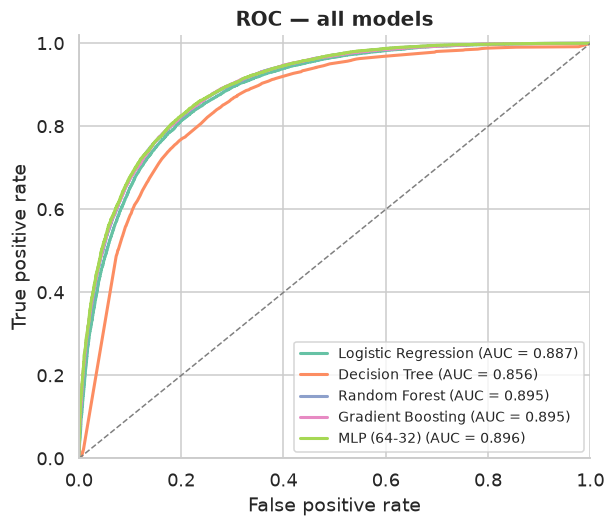

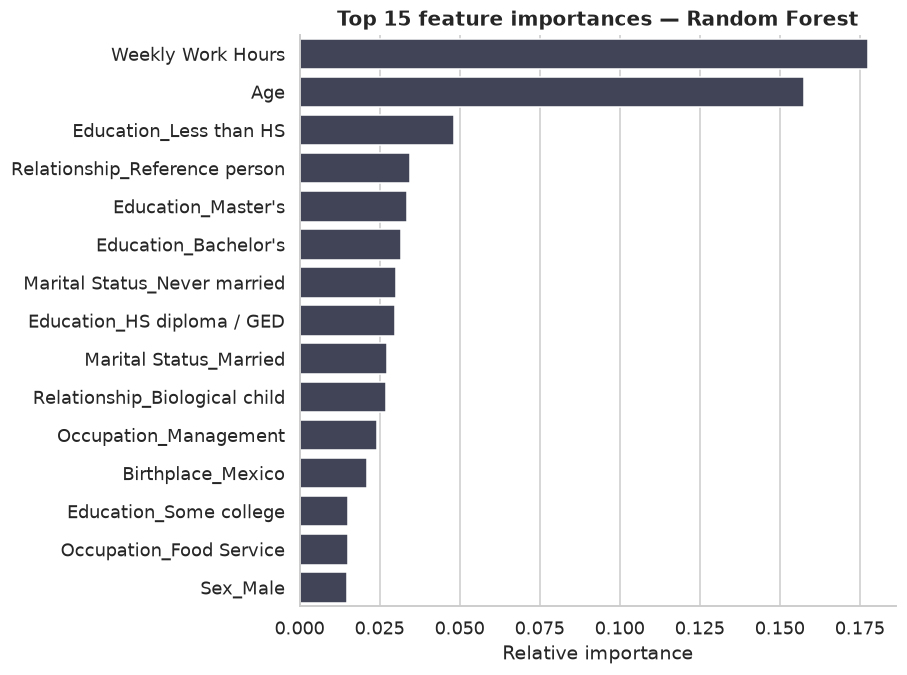

**Takeaway:** the top three one-hot/numeric features are Weekly Work Hours, Age, Education_Less than HS (38% of total importance).

In [14]:
V.save(V.plot_roc_curve({n: (y_test, m.score(X_test)) for n, m in fitted.items()}, "ROC — all models"), FIG_DIR, "14_roc_all"); plt.show()
clf = best.pipeline.named_steps["classifier"]
if hasattr(clf, "feature_importances_"):
    imp, lab = clf.feature_importances_, f"{best_name}"
else:
    tree = fitted["Gradient Boosting"]; imp, lab = tree.pipeline.named_steps["classifier"].feature_importances_, "Gradient Boosting"
    best_imp_model = tree
fn = (best if hasattr(clf, "feature_importances_") else fitted["Gradient Boosting"]).feature_names()
V.save(V.plot_feature_importance(imp, fn, title=f"Top 15 feature importances — {lab}"), FIG_DIR, "15_feature_importance"); plt.show()
top = pd.Series(imp, index=fn).sort_values(ascending=False)
say(f"**Takeaway:** the top three one-hot/numeric features are {', '.join(top.index[:3])} "
    f"({top.iloc[:3].sum():.0%} of total importance).")

## 6 · Fairness peek (best model)
True-positive rate (share of actual >50K earners the model catches) and predicted-positive rate per group, next to each group's true base rate. Groups with fewer than 50 test rows are hidden.

,n,Base rate,Predicted positive rate,TPR
Sex,,,,
Male,20720,46.7%,51.5%,83.8%
Female,18413,34.7%,37.4%,78.0%


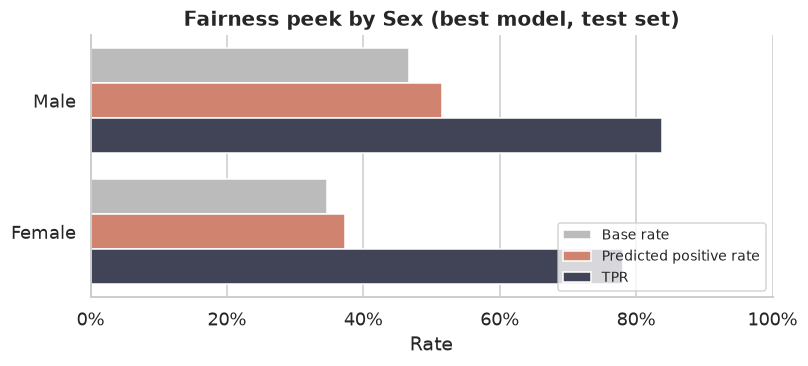

**Sex:** TPR ranges 78% (Female) → 84% (Male); predicted-positive rate ranges 37% → 51% (true base rates 35% → 47%).

,n,Base rate,Predicted positive rate,TPR
Race,,,,
White,24075,44.3%,49.1%,83.8%
Asian,6577,47.8%,54.2%,85.5%
Some Other Race,4596,19.6%,15.4%,49.0%
Black,1758,34.2%,37.9%,73.4%
Two or More Races,1659,37.9%,39.9%,79.1%
American Indian,236,28.8%,30.1%,70.6%
NHPI,133,27.1%,27.8%,66.7%
AIAN tribe / not specified,94,21.3%,25.5%,70.0%


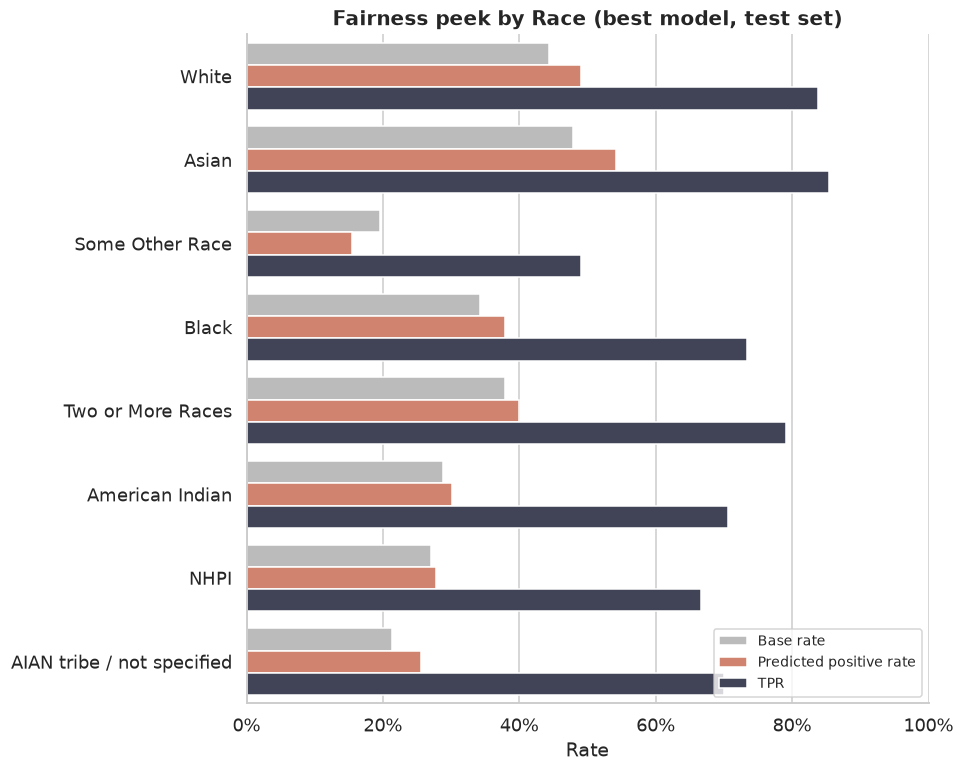

**Race:** TPR ranges 49% (Some Other Race) → 85% (Asian); predicted-positive rate ranges 15% → 54% (true base rates 20% → 48%).

In [15]:
yp = best.classify(X_test)
for attr in cfg["sensitive_cols"]:
    tab = M.group_rates(y_test, yp, X_test[attr])
    display(tab.rename_axis(attr).style.format({"Base rate": "{:.1%}", "Predicted positive rate": "{:.1%}", "TPR": "{:.1%}"}))
    V.save(V.fairness_bars(tab, attr), FIG_DIR, f"16_fairness_{attr.lower()}"); plt.show()
    say(f"**{attr}:** TPR ranges {tab['TPR'].min():.0%} ({tab['TPR'].idxmin()}) → {tab['TPR'].max():.0%} ({tab['TPR'].idxmax()}); "
        f"predicted-positive rate ranges {tab['Predicted positive rate'].min():.0%} → {tab['Predicted positive rate'].max():.0%} "
        f"(true base rates {tab['Base rate'].min():.0%} → {tab['Base rate'].max():.0%}).")

## 7 · Why look beyond Adult? — "Retiring Adult" (Ding, Hardt, Miller & Schmidt, NeurIPS 2021)
- Adult comes from the **1994** Current Population Survey; the **$50K threshold** is not adjusted for inflation, so the label means something very different today and the base rate is artificially low.
- Its small size (~48K rows) and fixed snapshot limit studies of how fairness interventions behave across **states and years**.
- The authors released **folktables**, which builds Adult-like tasks from the US Census **American Community Survey (ACS) PUMS**. `ACSIncome` keeps the >$50K target and a similar feature set, filtered to employed adults (age > 16, worked ≥ 1 h/week, income > $100).

**Swap:** set `DATASET = "acs_income"` in the top cell and re-run. `src/datasets.py` maps the numeric PUMS codes (SEX, RAC1P, MAR, COW, RELP) to readable labels from the official 2018 PUMS data dictionary, bands SCHL into education levels, and groups OCCP/POBP into occupation families / birth regions, so every downstream cell works unchanged. Differences to keep in mind: ACSIncome has no capital gain/loss or education-years columns (only Age and Weekly Work Hours are numeric), it is ~4× larger, and its >50K base rate is much higher.

In [16]:
say(f"**This run:** `{DATASET}` · {len(df):,} rows · base rate {base:.1%} · baseline F1 {bm['F1']:.3f} / AUC {bm['ROC-AUC']:.3f} · "
    f"best {best_name} F1 {res.loc[0,'F1']:.3f} / AUC {res.loc[0,'ROC-AUC']:.3f}. Saved {len(list(FIG_DIR.glob('*.png')))} figures to `{FIG_DIR.relative_to(PROJECT_ROOT)}`.")

**This run:** `acs_income` · 195,665 rows · base rate 41.1% · baseline F1 0.776 / AUC 0.887 · best Random Forest F1 0.779 / AUC 0.895. Saved 17 figures to `reports/figures/acs_income`.